## 1. Bibliotecas

Uso `pandas` para trabalhar com as tabelas, `matplotlib` para os gráficos e `scikit-learn` para preparar os dados, treinar os modelos e calcular as métricas.

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Abrir os CSVs e entender os dados

Deixe os arquivos originais na mesma pasta do notebook. No ambiente deste case, o código também procura os arquivos na pasta de upload.

In [30]:
nome_historico = 'transacoes_historico_2025.csv'
nome_janeiro = 'transacoes_jan2026.csv'
pasta_dados = Path('.')
if not (pasta_dados / nome_historico).exists():
    pasta_dados = Path('ATF-DataScience')

df = pd.read_csv(pasta_dados / nome_historico)
df_janeiro = pd.read_csv(pasta_dados / nome_janeiro)

print('Histórico:', df.shape)
print('Janeiro:', df_janeiro.shape)
print('Fraudes no histórico:', int(df['flag_fraude'].sum()))
print('Taxa de fraude em 2025: {:.2%}'.format(df['flag_fraude'].mean()))
print('Janeiro possui rótulo real?', 'flag_fraude' in df_janeiro.columns)

# Inspeção básica pedida em um projeto de análise
df.info()
print('Primeiras linhas do histórico:')
display(df.head())
print('Resumo das variáveis numéricas:')
display(df.describe())
print('Valores vazios por coluna:')
display(df.isnull().sum())
print('Linhas duplicadas no histórico:', int(df.duplicated().sum()))

Histórico: (523525, 15)
Janeiro: (44451, 14)
Fraudes no histórico: 20485
Taxa de fraude em 2025: 3.91%
Janeiro possui rótulo real? False
<class 'pandas.DataFrame'>
RangeIndex: 523525 entries, 0 to 523524
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   datahora_transacao    523525 non-null  str    
 1   nome_estabelecimento  523525 non-null  str    
 2   tipo_estabelecimento  523525 non-null  str    
 3   valor_transacao       523525 non-null  float64
 4   nome_cliente          523525 non-null  str    
 5   cidade                523525 non-null  str    
 6   flag_fraude           523525 non-null  bool   
 7   device_type           523525 non-null  str    
 8   is_new_device         523525 non-null  bool   
 9   temperatura_celsius   523525 non-null  float64
 10  codigo_postal         523525 non-null  str    
 11  score_interno         523525 non-null  int64  
 12  turno                 523525 n

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


Resumo das variáveis numéricas:


,valor_transacao,temperatura_celsius,score_interno
count,523525.000000,523525.000000,523525.000000
mean,43.962948,24.005198,500.373539
std,74.408984,6.921326,288.921133
min,0.500000,-12.700000,0.000000
25%,14.260000,19.500000,250.000000
50%,25.250000,25.200000,500.000000
75%,44.950000,29.200000,751.000000
max,722.900000,46.100000,1000.000000


Valores vazios por coluna:


datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
flag_fraude             0
device_type             0
is_new_device           0
temperatura_celsius     0
codigo_postal           0
score_interno           0
turno                   0
valor_categoria         0
cidade_regiao           0
dtype: int64

Linhas duplicadas no histórico: 0


## 3. Exploração inicial

Fraudes são uma classe rara. Por isso, vou olhar as taxas de fraude por mês e por alguns grupos antes de treinar. Essas taxas são associações observadas nos dados, não provam causa.

mes
2025-01    3.73
2025-02    3.70
2025-03    3.80
2025-04    3.82
2025-05    3.70
2025-06    3.82
2025-07    3.99
2025-08    3.71
2025-09    3.75
2025-10    3.81
2025-11    3.67
2025-12    5.42
Name: fraude (%), dtype: float64

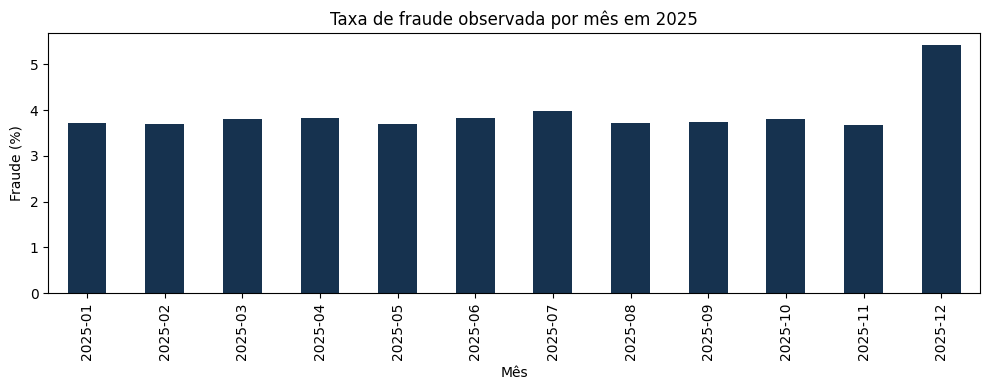

In [32]:
df['datahora_transacao'] = pd.to_datetime(df['datahora_transacao'])
df_janeiro['datahora_transacao'] = pd.to_datetime(df_janeiro['datahora_transacao'])

df['mes'] = df['datahora_transacao'].dt.to_period('M').astype(str)
taxa_por_mes = (df.groupby('mes')['flag_fraude'].mean() * 100).round(2)
display(taxa_por_mes.rename('fraude (%)'))

fig, ax = plt.subplots(figsize=(10, 4))
taxa_por_mes.plot(kind='bar', color='#16324F', ax=ax)
ax.set_title('Taxa de fraude observada por mês em 2025')
ax.set_ylabel('Fraude (%)')
ax.set_xlabel('Mês')
plt.tight_layout()
plt.show()

In [33]:
print('Taxa por uso de dispositivo novo:')
display((df.groupby('is_new_device')['flag_fraude'].mean() * 100).round(2))
print('Taxa por turno:')
display((df.groupby('turno')['flag_fraude'].mean() * 100).round(2))
print('Taxa por tipo de estabelecimento:')
display((df.groupby('tipo_estabelecimento')['flag_fraude'].mean() * 100).sort_values(ascending=False).round(2))

print('Distribuição da classe-alvo:')
display(df['flag_fraude'].value_counts().rename(index={False: 'nao_fraude', True: 'fraude'}))

Taxa por uso de dispositivo novo:


is_new_device
False     2.13
True     12.90
Name: flag_fraude, dtype: float64

Taxa por turno:


turno
madrugada     1.35
manha         0.66
noite        10.24
tarde         3.40
Name: flag_fraude, dtype: float64

Taxa por tipo de estabelecimento:


tipo_estabelecimento
Fuel               7.55
Food & Beverage    6.63
E-commerce         3.12
Retail             2.51
Supermarket        2.37
Pharmacy           2.33
Name: flag_fraude, dtype: float64

Distribuição da classe-alvo:


flag_fraude
nao_fraude    503040
fraude         20485
Name: count, dtype: int64

A taxa de fraude é baixa no conjunto, então a **acurácia sozinha pode enganar**: um modelo que sempre previsse “não fraude” acertaria muitas linhas, mas não encontraria nenhuma fraude. Vou dar destaque a PR-AUC, precisão, recall e F1.

## 4. Criar variáveis de calendário

A data completa não entra diretamente no modelo. Extraio três informações fáceis de explicar: hora, dia da semana e se é fim de semana. Mantenho uma cópia original de janeiro para que o CSV final não ganhe colunas técnicas desnecessárias.

In [34]:
df['hora'] = df['datahora_transacao'].dt.hour
df['dia_semana'] = df['datahora_transacao'].dt.day_of_week
df['fim_de_semana'] = (df['dia_semana'] >= 5).astype(int)

df_janeiro_original = df_janeiro.copy()
df_janeiro['hora'] = df_janeiro['datahora_transacao'].dt.hour
df_janeiro['dia_semana'] = df_janeiro['datahora_transacao'].dt.day_of_week
df_janeiro['fim_de_semana'] = (df_janeiro['dia_semana'] >= 5).astype(int)

colunas_categoricas = [
    'tipo_estabelecimento', 'device_type', 'is_new_device',
    'valor_categoria', 'turno', 'cidade'
]
colunas_numericas = [
    'valor_transacao', 'temperatura_celsius', 'score_interno',
    'hora', 'dia_semana', 'fim_de_semana'
]
colunas_modelo = colunas_categoricas + colunas_numericas

print('Número de variáveis usadas:', len(colunas_modelo))
print('Variáveis excluídas:', ['nome_cliente', 'codigo_postal', 'nome_estabelecimento', 'datahora_transacao bruta'])

Número de variáveis usadas: 12
Variáveis excluídas: ['nome_cliente', 'codigo_postal', 'nome_estabelecimento', 'datahora_transacao bruta']


## 5. Separar treino, validação e teste por data

A ordem temporal evita que meses futuros ajudem o modelo a prever meses passados. O treino vai de janeiro a setembro; a validação usa outubro e novembro; dezembro fica reservado como teste final.

In [35]:
mascara_treino = df['datahora_transacao'] < '2025-10-01'
mascara_validacao = (
    (df['datahora_transacao'] >= '2025-10-01') &
    (df['datahora_transacao'] < '2025-12-01')
)
mascara_teste = df['datahora_transacao'] >= '2025-12-01'

X_treino = df.loc[mascara_treino, colunas_modelo]
y_treino = df.loc[mascara_treino, 'flag_fraude'].astype(int)
X_validacao = df.loc[mascara_validacao, colunas_modelo]
y_validacao = df.loc[mascara_validacao, 'flag_fraude'].astype(int)
X_teste = df.loc[mascara_teste, colunas_modelo]
y_teste = df.loc[mascara_teste, 'flag_fraude'].astype(int)

resumo_particoes = pd.DataFrame({
    'transacoes': [len(y_treino), len(y_validacao), len(y_teste)],
    'fraudes': [int(y_treino.sum()), int(y_validacao.sum()), int(y_teste.sum())],
    'taxa_fraude (%)': [100*y_treino.mean(), 100*y_validacao.mean(), 100*y_teste.mean()]
}, index=['Treino jan-set', 'Validação out-nov', 'Teste dez'])
display(resumo_particoes.round(2))

,transacoes,fraudes,taxa_fraude (%)
Treino jan-set,391566,14801,3.78
Validação out-nov,87508,3273,3.74
Teste dez,44451,2411,5.42


## 6. Preparar os dados e treinar dois modelos

Vou comparar um **baseline de regressão logística** com **gradient boosting**. A regressão logística é um ponto de comparação simples. O boosting combina várias árvores pequenas e consegue aprender relações não lineares.

`OneHotEncoder` converte categorias em colunas indicadoras. No modelo linear, também padronizo as variáveis numéricas. O preparo fica dentro de `Pipeline`, então é ajustado somente no treino e aplicado da mesma forma à validação e ao teste.

In [36]:
# Baseline: categorias em indicadores e números padronizados
preparo_logistico = ColumnTransformer(
    transformers=[
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
        ('numericas', StandardScaler(), colunas_numericas),
    ]
)
modelo_logistico = Pipeline(steps=[
    ('preparo', preparo_logistico),
    ('modelo', LogisticRegression(class_weight='balanced', max_iter=300, random_state=42)),
])

# Modelo não linear: mantém os números na escala original
preparo_boosting = ColumnTransformer(
    transformers=[
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
        ('numericas', 'passthrough', colunas_numericas),
    ],
    sparse_threshold=0.0,
)
modelo_boosting = Pipeline(steps=[
    ('preparo', preparo_boosting),
    ('modelo', HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=120,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42,
    )),
])

modelo_logistico.fit(X_treino, y_treino)
modelo_boosting.fit(X_treino, y_treino)

prob_logistica_validacao = modelo_logistico.predict_proba(X_validacao)[:, 1]
prob_boosting_validacao = modelo_boosting.predict_proba(X_validacao)[:, 1]

## 7. Comparar os modelos na validação

Como a fraude é rara, uso **PR-AUC** como métrica principal para escolher o modelo. ROC-AUC aparece como medida complementar. O conjunto de dezembro ainda não foi consultado nesta escolha.

,PR-AUC validação,ROC-AUC validação
Modelo,,
Regressão logística (baseline),0.226,0.898
Gradient boosting,0.660,0.985


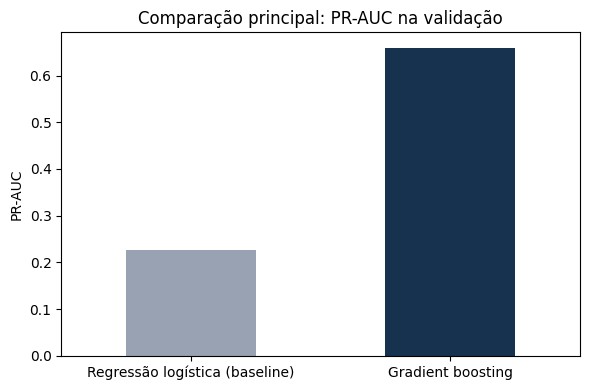

In [37]:
ap_logistica = average_precision_score(y_validacao, prob_logistica_validacao)
ap_boosting = average_precision_score(y_validacao, prob_boosting_validacao)
roc_logistica = roc_auc_score(y_validacao, prob_logistica_validacao)
roc_boosting = roc_auc_score(y_validacao, prob_boosting_validacao)

comparacao = pd.DataFrame({
    'Modelo': ['Regressão logística (baseline)', 'Gradient boosting'],
    'PR-AUC validação': [ap_logistica, ap_boosting],
    'ROC-AUC validação': [roc_logistica, roc_boosting],
}).set_index('Modelo')
display(comparacao.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
comparacao['PR-AUC validação'].plot(kind='bar', color=['#98A2B3', '#16324F'], ax=ax)
ax.set_title('Comparação principal: PR-AUC na validação')
ax.set_ylabel('PR-AUC')
ax.set_xlabel('')
plt.xticks(rotation=0, ha='center')
plt.tight_layout()
plt.show()

In [12]:
# Escolher pelo PR-AUC de validação, sem usar os resultados de dezembro
if ap_boosting >= ap_logistica:
    nome_modelo_escolhido = 'Gradient boosting'
    modelo_escolhido = modelo_boosting
    prob_validacao = prob_boosting_validacao
else:
    nome_modelo_escolhido = 'Regressão logística'
    modelo_escolhido = modelo_logistico
    prob_validacao = prob_logistica_validacao

print('Modelo escolhido:', nome_modelo_escolhido)
print('Motivo: maior PR-AUC na validação temporal.')

Modelo escolhido: Gradient boosting
Motivo: maior PR-AUC na validação temporal.


## 8. Escolher o limiar na validação

O modelo produz probabilidades; para gerar uma classe, é preciso escolher um corte. Sem uma matriz de custos fornecida, uso o **maior F1** na validação, que equilibra precisão e recall. O limiar fica congelado antes de abrir o teste de dezembro.

In [38]:
precisoes, recalls, limiares = precision_recall_curve(y_validacao, prob_validacao)
f1s = 2 * precisoes[:-1] * recalls[:-1] / (precisoes[:-1] + recalls[:-1] + 1e-10)
melhor_indice = np.argmax(f1s)
limiar = limiares[melhor_indice]

print('Limiar escolhido:', round(limiar, 3))
print('Precisão na validação:', round(precisoes[melhor_indice], 3))
print('Recall na validação:', round(recalls[melhor_indice], 3))
print('F1 na validação:', round(f1s[melhor_indice], 3))

Limiar escolhido: 0.295
Precisão na validação: 0.551
Recall na validação: 0.739
F1 na validação: 0.631


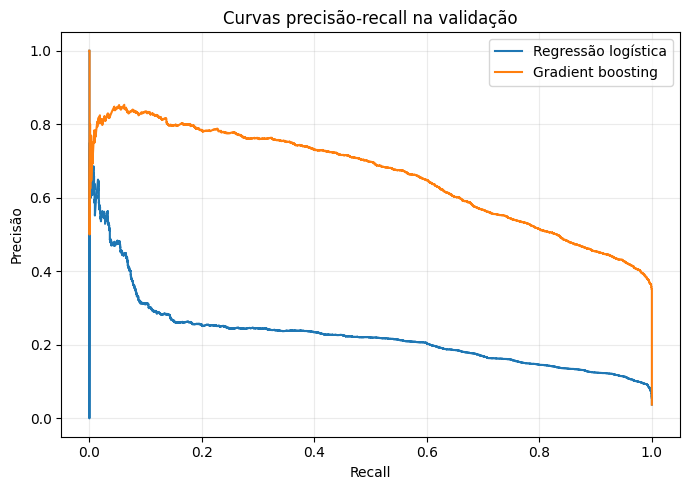

In [15]:
precisao_curva_log, recall_curva_log, _ = precision_recall_curve(y_validacao, prob_logistica_validacao)
precisao_curva_gb, recall_curva_gb, _ = precision_recall_curve(y_validacao, prob_boosting_validacao)

plt.figure(figsize=(7, 5))
plt.plot(recall_curva_log, precisao_curva_log, label='Regressão logística')
plt.plot(recall_curva_gb, precisao_curva_gb, label='Gradient boosting')
plt.xlabel('Recall')
plt.ylabel('Precisão')
plt.title('Curvas precisão-recall na validação')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Avaliar uma vez no teste temporal

Agora aplico o modelo e o limiar já escolhidos a dezembro. A matriz de confusão separa verdadeiros e falsos positivos/negativos. Também mostro acurácia balanceada e especificidade, além das métricas principais.

In [39]:
prob_teste = modelo_escolhido.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste >= limiar).astype(int)
verdadeiros_negativos, falsos_positivos, falsos_negativos, verdadeiros_positivos = confusion_matrix(
    y_teste, pred_teste, labels=[0, 1]
).ravel()

metricas_teste = pd.Series({
    'Precisão': precision_score(y_teste, pred_teste),
    'Recall': recall_score(y_teste, pred_teste),
    'F1': f1_score(y_teste, pred_teste),
    'PR-AUC': average_precision_score(y_teste, prob_teste),
    'ROC-AUC': roc_auc_score(y_teste, prob_teste),
    'Acurácia balanceada': balanced_accuracy_score(y_teste, pred_teste),
    'Especificidade': verdadeiros_negativos / (verdadeiros_negativos + falsos_positivos),
})
display(metricas_teste.round(3).rename('dezembro'))

print('Matriz de confusão [ [VN, FP], [FN, VP] ]:')
print(confusion_matrix(y_teste, pred_teste, labels=[0, 1]))

Precisão               0.610
Recall                 0.643
F1                     0.626
PR-AUC                 0.701
ROC-AUC                0.980
Acurácia balanceada    0.810
Especificidade         0.976
Name: dezembro, dtype: float64

Matriz de confusão [ [VN, FP], [FN, VP] ]:
[[41048   992]
 [  860  1551]]


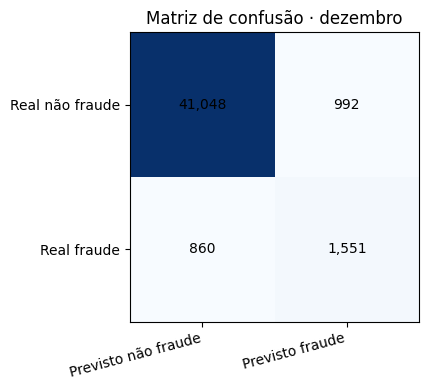

In [40]:
matriz = confusion_matrix(y_teste, pred_teste, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(matriz, cmap='Blues')
ax.set_xticks([0, 1], labels=['Previsto não fraude', 'Previsto fraude'])
ax.set_yticks([0, 1], labels=['Real não fraude', 'Real fraude'])
ax.set_title('Matriz de confusão · dezembro')
for (i, j), valor in np.ndenumerate(matriz):
    ax.text(j, i, f'{valor:,}', ha='center', va='center', color='black')
plt.setp(ax.get_xticklabels(), rotation=15, ha='right')
plt.tight_layout()
plt.show()

### Checagem de probabilidade: Brier score

AUC mede ordenação; o Brier score mede o erro das probabilidades (menor é melhor). Comparo o modelo com uma referência simples que atribui a todas as linhas a taxa de fraude observada no treino.

In [41]:
brier_modelo = brier_score_loss(y_teste, prob_teste)
probabilidade_referencia = np.repeat(y_treino.mean(), len(y_teste))
brier_referencia = brier_score_loss(y_teste, probabilidade_referencia)

print('Brier do modelo:', round(brier_modelo, 4))
print('Brier da referência constante:', round(brier_referencia, 4))
print('Probabilidade média prevista no teste: {:.2%}'.format(prob_teste.mean()))
print('Fraude realmente observada no teste: {:.2%}'.format(y_teste.mean()))

Brier do modelo: 0.0269
Brier da referência constante: 0.0516
Probabilidade média prevista no teste: 4.12%
Fraude realmente observada no teste: 5.42%


## 10. Explicar o modelo com importância por permutação

Em cada repetição, embaralho uma variável da validação e meço quanto cai a PR-AUC. Uma queda maior indica que o modelo depende mais daquela informação para ordenar os casos. Isso **não é causalidade**; variáveis correlacionadas podem dividir importância.

In [43]:
importancias = permutation_importance(
    modelo_escolhido,
    X_validacao,
    y_validacao,
    scoring='average_precision',
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)

resumo_importancia = pd.DataFrame({
    'variavel': colunas_modelo,
    'queda_media_PR_AUC': importancias.importances_mean,
    'desvio_entre_repeticoes': importancias.importances_std,
}).sort_values('queda_media_PR_AUC', ascending=False)
display(resumo_importancia.head(10).round(3))

,variavel,queda_media_PR_AUC,desvio_entre_repeticoes
9,hora,0.548,0.008
0,tipo_estabelecimento,0.321,0.008
2,is_new_device,0.206,0.011
5,cidade,0.172,0.005
6,valor_transacao,0.137,0.004
4,turno,0.096,0.004
1,device_type,0.029,0.002
7,temperatura_celsius,0.011,0.000
8,score_interno,0.006,0.001
10,dia_semana,0.005,0.000


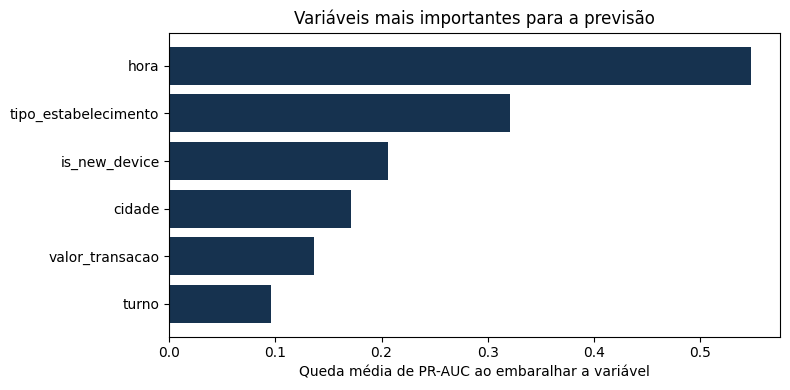

In [44]:
principais = resumo_importancia.head(6).sort_values('queda_media_PR_AUC')
plt.figure(figsize=(8, 4))
plt.barh(principais['variavel'], principais['queda_media_PR_AUC'], color='#16324F')
plt.xlabel('Queda média de PR-AUC ao embaralhar a variável')
plt.title('Variáveis mais importantes para a previsão')
plt.tight_layout()
plt.show()

## 11. Treinar a versão final e classificar todas as transações de janeiro

Depois de medir o desempenho em dezembro, reajusto o modelo escolhido com todos os rótulos de 2025. Mantenho o limiar definido na validação e aplico a todas as linhas de janeiro. O resultado inclui a classe e a probabilidade previstas.

In [45]:
# Reajustar o modelo escolhido com todo o histórico rotulado de 2025
modelo_final = modelo_escolhido
modelo_final.fit(df[colunas_modelo], df['flag_fraude'].astype(int))

X_janeiro = df_janeiro[colunas_modelo]
prob_janeiro = modelo_final.predict_proba(X_janeiro)[:, 1]

df_resultado = df_janeiro_original.copy()
df_resultado['probabilidade_fraude'] = prob_janeiro
df_resultado['classificacao_fraude'] = np.where(
    prob_janeiro >= limiar, 'fraude', 'nao_fraude'
)

arquivo_saida = 'transacoes_jan2026_classificadas.csv'
df_resultado.to_csv(arquivo_saida, index=False, float_format='%.6f')
print('Arquivo salvo:', Path(arquivo_saida).resolve())
print('Total de linhas classificadas:', len(df_resultado))

Arquivo salvo: C:\Users\Andréia Salva\Downloads\transacoes_jan2026_classificadas.csv
Total de linhas classificadas: 44451


In [46]:
contagem_classes = df_resultado['classificacao_fraude'].value_counts().rename('transacoes')
percentual_classes = (df_resultado['classificacao_fraude'].value_counts(normalize=True) * 100).rename('percentual (%)')
resumo_janeiro = pd.concat([contagem_classes, percentual_classes], axis=1)
display(resumo_janeiro.round(2))

print('Probabilidade média estimada:', '{:.2%}'.format(df_resultado['probabilidade_fraude'].mean()))
print('Valor total das transações previstas como fraude: R$ {:,.2f}'.format(
    df_resultado.loc[df_resultado['classificacao_fraude'] == 'fraude', 'valor_transacao'].sum()
))
display(df_resultado.head())

,transacoes,percentual (%)
classificacao_fraude,,
nao_fraude,41998,94.48
fraude,2453,5.52


Probabilidade média estimada: 3.93%
Valor total das transações previstas como fraude: R$ 73,017.23


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,probabilidade_fraude,classificacao_fraude
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.000130,nao_fraude
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.000147,nao_fraude
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.000470,nao_fraude
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.001140,nao_fraude
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.000367,nao_fraude


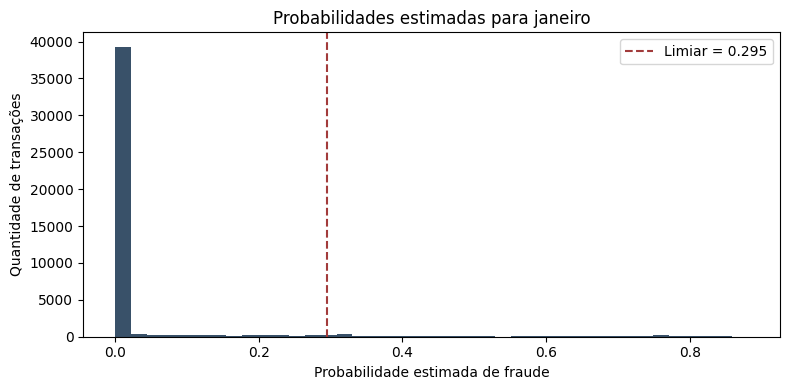

In [48]:
plt.figure(figsize=(8, 4))
plt.hist(prob_janeiro, bins=40, color='#16324F', alpha=0.85)
plt.axvline(limiar, color='#A23B3B', linestyle='--', label=f'Limiar = {limiar:.3f}')
plt.title('Probabilidades estimadas para janeiro')
plt.xlabel('Probabilidade estimada de fraude')
plt.ylabel('Quantidade de transações')
plt.legend()
plt.tight_layout()
plt.show()